In [ ]:
import re, itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy import stats
warnings.filterwarnings('ignore')

PATH_ROOM    = 'room night 2026.xlsx'
PATH_BANQUET = 'Mentahan.xlsx'

rng = np.random.default_rng(42)
N_SIM = 20000
BULAN = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

In [ ]:
import openpyxl

# --- room night per company: ambil baris total (tanpa nomor & nama perusahaan)
ws = openpyxl.load_workbook(PATH_ROOM, data_only=True)['ROOM NIGHT PER COMPANY']
rows = list(ws.iter_rows(values_only=True))
tot = [r for r in rows if r[1] is None and r[2] is None and isinstance(r[3], (int, float))][0]
rn, adr, rev = {}, {}, {}
for i, m in enumerate(BULAN):
    a, b, c = tot[3 + 3*i: 6 + 3*i]
    if a is not None:
        rn[m], adr[m], rev[m] = a, b, c

# --- target vs realisasi room night
ws = openpyxl.load_workbook(PATH_ROOM, data_only=True)['TARGET ROOM NIGHT']
tgt, real = {}, {}
nama_bulan = ['January','February','March','April','May','June','July','August','September','October','November','December']
for r in ws.iter_rows(values_only=True):
    if r[1] in nama_bulan:
        tgt[r[1][:3]], real[r[1][:3]] = r[2], r[3]

# --- banquet: ambil baris TOTAL tiap bulan (events & revenue definite+pickup)
ws = openpyxl.load_workbook(PATH_BANQUET, data_only=True)['Sheet2']
b_ev, b_rev, cur = {}, {}, None
for r in ws.iter_rows(values_only=True):
    if r[1] and isinstance(r[1], str) and r[1].startswith('DAILY BANQUET'):
        cur = r[1].split('-')[1].split()[0].title()
    if r[1] == 'TOTAL' and cur:
        b_ev[cur] = r[6]
        b_rev[cur] = float(re.sub(r'[^\d]', '', r[7]))
        cur = None

df = pd.DataFrame({'RN_corp': rn, 'ADR_corp': adr, 'REV_corp': rev,
                   'RN_realisasi': real, 'RN_target': tgt,
                   'Banquet_events': b_ev, 'Banquet_rev': b_rev}).reindex(BULAN)
df

,RN_corp,ADR_corp,REV_corp,RN_realisasi,RN_target,Banquet_events,Banquet_rev
Jan,195.0,783541.287179,1.527906e+08,545,396,26,480709086.0
Feb,291.0,742247.264605,2.159940e+08,20,438,18,335535636.0
Mar,217.0,791048.331797,1.716575e+08,144,209,18,243718189.0
Apr,328.0,731599.621951,2.399647e+08,202,931,16,458349000.0
May,250.0,748191.708000,1.870479e+08,182,838,22,333930035.0
Jun,385.0,766707.514286,2.951824e+08,563,1006,34,366417996.0
Jul,511.0,757193.851093,3.869261e+08,296,1016,19,481913635.0
Aug,352.0,806586.069673,2.839183e+08,469,991,29,656429357.0
Sep,678.0,799217.086389,5.418692e+08,344,989,21,788556349.0
Oct,NaN,NaN,NaN,463,1173,30,642976433.0


**Panjang series yang dipakai.** Series per perusahaan hanya tersedia Jan–Sep (n = 9). Untuk target, realisasi, dan banquet dipakai Jan–Okt (n = 10); Nov–Des dibuang karena masih berupa *booking* yang belum selesai.

In [ ]:
PANJANG = {'RN_corp': 9, 'ADR_corp': 9, 'REV_corp': 9,
           'RN_realisasi': 10, 'RN_target': 10, 'Banquet_events': 10, 'Banquet_rev': 10}

In [ ]:
def adf_stat(y, trend='c', lags=0):
    y = np.asarray(y, float); dy = np.diff(y); n = len(dy) - lags
    Y = dy[lags:]
    X = [y[lags:-1]] + [dy[lags - i:-i] for i in range(1, lags + 1)]
    X = np.column_stack(X + [np.ones(n)] + ([np.arange(n)] if trend == 'ct' else []))
    b, *_ = np.linalg.lstsq(X, Y, rcond=None)
    e = Y - X @ b
    s2 = e @ e / (n - X.shape[1])
    cov = s2 * np.linalg.inv(X.T @ X)
    return b[0] / np.sqrt(cov[0, 0])

def kpss_stat(y, trend='c', nlags=1):
    y = np.asarray(y, float); n = len(y)
    X = np.column_stack([np.ones(n)] + ([np.arange(n)] if trend == 'ct' else []))
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    e = y - X @ b
    s = e @ e / n
    for k in range(1, nlags + 1):                     # penaksir varians jangka panjang (Bartlett)
        s += 2 * (1 - k / (nlags + 1)) * (e[k:] @ e[:-k]) / n
    return (np.cumsum(e) ** 2).sum() / (n ** 2 * s)

_cache = {}
def _sim(kind, n, trend, nlags=1):
    key = (kind, n, trend, nlags)
    if key not in _cache:
        if kind == 'adf':
            _cache[key] = np.array([adf_stat(np.cumsum(rng.standard_normal(n)), trend) for _ in range(N_SIM)])
        else:
            _cache[key] = np.array([kpss_stat(rng.standard_normal(n), trend, nlags) for _ in range(N_SIM)])
    return _cache[key]

def adf_test(y, trend='c'):
    s = adf_stat(y, trend); d = _sim('adf', len(y), trend)
    return s, (d <= s).mean(), np.quantile(d, .05)         # stat, p-value, nilai kritis 5%

def kpss_test(y, trend='c', nlags=1):
    s = kpss_stat(y, trend, nlags); d = _sim('kpss', len(y), trend, nlags)
    return s, (d >= s).mean(), np.quantile(d, .95)

In [ ]:
hasil = []
for c, n in PANJANG.items():
    y = df[c].iloc[:n].values.astype(float)
    for bentuk, z in (('level', y), ('diff1', np.diff(y))):
        a, ap, ac = adf_test(z)
        k, kp, kc = kpss_test(z)
        hasil.append(dict(series=c, n=len(z), bentuk=bentuk, ADF=a, ADF_p=ap, ADF_krit5=ac,
                          KPSS=k, KPSS_p=kp, KPSS_krit5=kc))
stasioner = pd.DataFrame(hasil)
stasioner.round(3)

,series,n,bentuk,ADF,ADF_p,ADF_krit5,KPSS,KPSS_p,KPSS_krit5
0,RN_corp,9,level,-0.972,0.702,-3.331,0.537,0.001,0.405
1,RN_corp,8,diff1,-5.719,0.005,-3.468,0.229,0.342,0.399
2,ADR_corp,9,level,-2.414,0.167,-3.331,0.248,0.280,0.405
3,ADR_corp,8,diff1,-5.740,0.005,-3.468,0.288,0.206,0.399
4,REV_corp,9,level,-0.576,0.823,-3.331,0.528,0.002,0.405
5,REV_corp,8,diff1,-5.024,0.010,-3.468,0.259,0.267,0.399
6,RN_realisasi,10,level,-2.977,0.077,-3.278,0.257,0.240,0.410
7,RN_realisasi,9,diff1,-6.400,0.002,-3.331,0.234,0.314,0.405
8,RN_target,10,level,-1.303,0.580,-3.278,0.513,0.007,0.410
9,RN_target,9,diff1,-4.477,0.013,-3.331,0.111,0.820,0.405


In [ ]:
def vonis(r):
    adf_tolak, kpss_tolak = r.ADF_p < .05, r.KPSS_p < .05
    if (not adf_tolak) and kpss_tolak:   return 'TIDAK STASIONER'
    if adf_tolak and (not kpss_tolak):   return 'STASIONER'
    if (not adf_tolak) and (not kpss_tolak):
        return 'cenderung tidak stasioner' if r.KPSS_p < .10 else 'inkonklusif / cenderung stasioner'
    return 'kontradiktif'

lv = stasioner[stasioner.bentuk == 'level'].copy()
lv['kesimpulan'] = lv.apply(vonis, axis=1)
lv[['series', 'n', 'ADF_p', 'KPSS_p', 'kesimpulan']].round(3).reset_index(drop=True)

,series,n,ADF_p,KPSS_p,kesimpulan
0,RN_corp,9,0.702,0.001,TIDAK STASIONER
1,ADR_corp,9,0.167,0.280,inkonklusif / cenderung stasioner
2,REV_corp,9,0.823,0.002,TIDAK STASIONER
3,RN_realisasi,10,0.077,0.240,inkonklusif / cenderung stasioner
4,RN_target,10,0.580,0.007,TIDAK STASIONER
5,Banquet_events,10,0.077,0.207,inkonklusif / cenderung stasioner
6,Banquet_rev,10,0.706,0.056,cenderung tidak stasioner


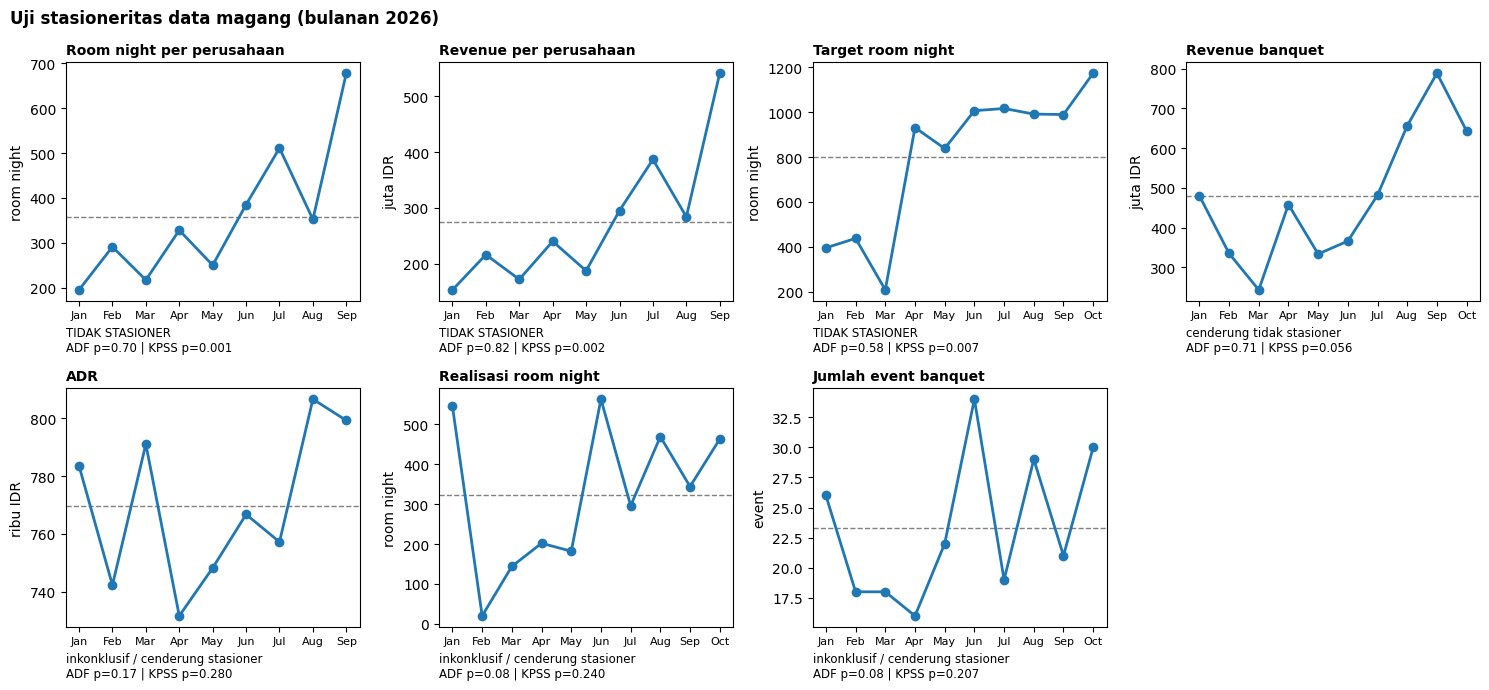

In [ ]:
panel = [  # kolom, judul, skala, satuan
    ('RN_corp', 'Room night per perusahaan', 1, 'room night'),
    ('REV_corp', 'Revenue per perusahaan', 1e6, 'juta IDR'),
    ('RN_target', 'Target room night', 1, 'room night'),
    ('Banquet_rev', 'Revenue banquet', 1e6, 'juta IDR'),
    ('ADR_corp', 'ADR', 1e3, 'ribu IDR'),
    ('RN_realisasi', 'Realisasi room night', 1, 'room night'),
    ('Banquet_events', 'Jumlah event banquet', 1, 'event')]
fig, axs = plt.subplots(2, 4, figsize=(15, 7))
for ax, (c, ttl, sc, unit) in zip(axs.flat, panel):
    n = PANJANG[c]; v = df[c].iloc[:n].values / sc
    r = lv[lv.series == c].iloc[0]
    ax.axhline(v.mean(), color='gray', ls='--', lw=1)
    ax.plot(range(n), v, marker='o', lw=2)
    ax.set_xticks(range(n)); ax.set_xticklabels(BULAN[:n], fontsize=8)
    ax.set_title(ttl, loc='left', fontsize=10, fontweight='bold')
    ax.set_xlabel(f"{r.kesimpulan}\nADF p={r.ADF_p:.2f} | KPSS p={r.KPSS_p:.3f}", fontsize=8.5, loc='left')
    ax.set_ylabel(unit)
axs.flat[7].axis('off')
plt.suptitle('Uji stasioneritas data magang (bulanan 2026)', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

In [ ]:
def _unpack(par, p, q, drift, reg):
    i = 0; c = b = 0.0
    if drift: c = par[i]; i += 1
    if reg:   b = par[i]; i += 1
    return c, b, par[i:i + p], par[i + p:i + p + q]

def _resid(par, dy, dx, p, q, drift, reg):
    c, b, phi, th = _unpack(par, p, q, drift, reg)
    z = dy - c - b * dx
    e = np.zeros(len(z))
    for t in range(len(z)):
        ar = sum(phi[i] * z[t-1-i] for i in range(p) if t-1-i >= 0)
        ma = sum(th[j] * e[t-1-j] for j in range(q) if t-1-j >= 0)
        e[t] = z[t] - ar - ma
    return e, z

def fit_regarima(y, x, p=0, q=0, drift=False, reg=True):
    dy, dx = np.diff(y), np.diff(x)
    k = int(drift) + int(reg) + p + q
    start = np.zeros(k)
    if reg or drift:                                   # titik awal dari OLS
        X = np.column_stack(([np.ones(len(dy))] if drift else []) + ([dx] if reg else []))
        start[:X.shape[1]] = np.linalg.lstsq(X, dy, rcond=None)[0]
    if p + q > 0:
        bnds = [(None, None)] * (int(drift) + int(reg)) + [(-.95, .95)] * (p + q)
        par = minimize(lambda a: np.sum(_resid(a, dy, dx, p, q, drift, reg)[0][p:] ** 2),
                       start, method='L-BFGS-B', bounds=bnds).x
    else:
        par = start
    e, z = _resid(par, dy, dx, p, q, drift, reg)
    ne = len(e) - p; sse = np.sum(e[p:] ** 2)
    s2 = sse / max(ne - k, 1)
    aic = ne * np.log(sse / ne) + 2 * (k + 1)
    aicc = aic + 2 * (k + 1) * (k + 2) / max(ne - k - 2, 1e-9)
    return dict(par=par, p=p, q=q, drift=drift, reg=reg, e=e, z=z, s2=s2, aic=aic, aicc=aicc, k=k)

def forecast_1step(m, y, x, x_next):
    c, b, phi, th = _unpack(m['par'], m['p'], m['q'], m['drift'], m['reg'])
    z, e = m['z'], m['e']
    ar = sum(phi[i] * z[-1-i] for i in range(m['p']) if len(z) > i)
    ma = sum(th[j] * e[-1-j] for j in range(m['q']) if len(e) > j)
    return y[-1] + c + b * (x_next - x[-1]) + ar + ma

In [ ]:
# data: Revenue (juta IDR) dan Room Night per perusahaan, Jan-Sep
n = PANJANG['REV_corp']
y = (df['REV_corp'].iloc[:n] / 1e6).values
x = df['RN_corp'].iloc[:n].values.astype(float)
bulan = BULAN[:n]

# pemilihan model (d = 1) berdasarkan AICc
rows = []
for (p, q), drift, reg in itertools.product([(0,0), (1,0), (0,1)], [True, False], [True, False]):
    m = fit_regarima(y, x, p, q, drift, reg)
    rows.append(dict(spesifikasi=f"ARIMA({p},1,{q}) drift={'Y' if drift else 'N'} xreg={'Y' if reg else 'N'}",
                     p=p, q=q, drift=drift, reg=reg, k=m['k'], AIC=m['aic'], AICc=m['aicc'], sigma=np.sqrt(m['s2'])))
seleksi = pd.DataFrame(rows).sort_values('AICc').reset_index(drop=True)
seleksi.drop(columns=['p','q','drift','reg']).round(2)

,spesifikasi,k,AIC,AICc,sigma
0,"ARIMA(0,1,0) drift=N xreg=Y",1,42.19,44.59,11.63
1,"ARIMA(1,1,0) drift=N xreg=Y",2,38.97,46.97,12.47
2,"ARIMA(0,1,0) drift=Y xreg=Y",2,42.97,48.97,11.64
3,"ARIMA(0,1,1) drift=N xreg=Y",2,44.06,50.06,12.46
4,"ARIMA(0,1,1) drift=Y xreg=Y",3,44.82,58.15,12.63
5,"ARIMA(1,1,0) drift=Y xreg=Y",3,39.51,59.51,12.56
6,"ARIMA(1,1,0) drift=N xreg=N",1,68.28,71.28,106.55
7,"ARIMA(1,1,0) drift=Y xreg=N",2,66.40,74.40,88.47
8,"ARIMA(0,1,0) drift=N xreg=N",0,78.28,78.95,117.63
9,"ARIMA(0,1,1) drift=Y xreg=N",2,74.52,80.52,83.63


In [ ]:
best = seleksi[seleksi.reg].iloc[0]                       # model terbaik yang memakai regresor
P, Q, DRIFT = int(best.p), int(best.q), bool(best.drift)
model = fit_regarima(y, x, P, Q, DRIFT, True)
c_, beta, phi, theta = _unpack(model['par'], P, Q, DRIFT, True)
sigma = np.sqrt(model['s2'])
print('Model terpilih :', best.spesifikasi)
print(f'beta = {beta:.3f} juta IDR per room night   (ADR rata-rata = {df.ADR_corp.iloc[:n].mean()/1e6:.3f} juta)')
print(f'sigma = {sigma:.2f}')

res = model['e']
print('\nDiagnostik residual')
print('  Shapiro-Wilk p =', round(stats.shapiro(res).pvalue, 3), '(>0.05 → normal)')
print('  Autokorelasi lag-1 =', round(np.corrcoef(res[:-1], res[1:])[0, 1], 3))

Model terpilih : ARIMA(0,1,0) drift=N xreg=Y
beta = 0.743 juta IDR per room night   (ADR rata-rata = 0.770 juta)
sigma = 11.63

Diagnostik residual
  Shapiro-Wilk p = 0.495 (>0.05 → normal)
  Autokorelasi lag-1 = -0.23


In [ ]:
def holt(y_tr):
    def sse(a):
        al, be = a; l, b = y_tr[0], y_tr[1] - y_tr[0]; s = 0
        for t in range(1, len(y_tr)):
            s += (y_tr[t] - (l + b)) ** 2
            ln = al * y_tr[t] + (1 - al) * (l + b); b = be * (ln - l) + (1 - be) * b; l = ln
        return s
    al, be = minimize(sse, [.5, .3], bounds=[(.01, .99)] * 2, method='L-BFGS-B').x
    l, b = y_tr[0], y_tr[1] - y_tr[0]
    for t in range(1, len(y_tr)):
        ln = al * y_tr[t] + (1 - al) * (l + b); b = be * (ln - l) + (1 - be) * b; l = ln
    return l + b                                           # prediksi 1 langkah

bt = []
for T in range(6, n):
    ytr, xtr = y[:T], x[:T]
    m_reg = fit_regarima(ytr, xtr, P, Q, DRIFT, True)
    bt.append(dict(bulan=bulan[T], aktual=y[T], RN=x[T],
                   RegARIMA=forecast_1step(m_reg, ytr, xtr, x[T]),
                   Holt=holt(ytr), sigma=np.sqrt(m_reg['s2'])))
bt = pd.DataFrame(bt)
metode = ['RegARIMA', 'Holt']
metrik = pd.DataFrame({m: dict(RMSE=np.sqrt(((bt.aktual - bt[m]) ** 2).mean()),
                               MAE=(bt.aktual - bt[m]).abs().mean(),
                               MAPE=((bt.aktual - bt[m]).abs() / bt.aktual).mean() * 100)
                       for m in metode}).T
display(bt.round(1)); display(metrik.round(2))

,bulan,aktual,RN,RegARIMA,Holt,sigma
0,Jul,386.9,511.0,382.7,285.5,9.3
1,Aug,283.9,352.0,275.2,444.4,8.5
2,Sep,541.9,678.0,508.1,350.7,8.3


,RMSE,MAE,MAPE
RegARIMA,20.28,15.56,3.46
Holt,155.56,151.03,39.34


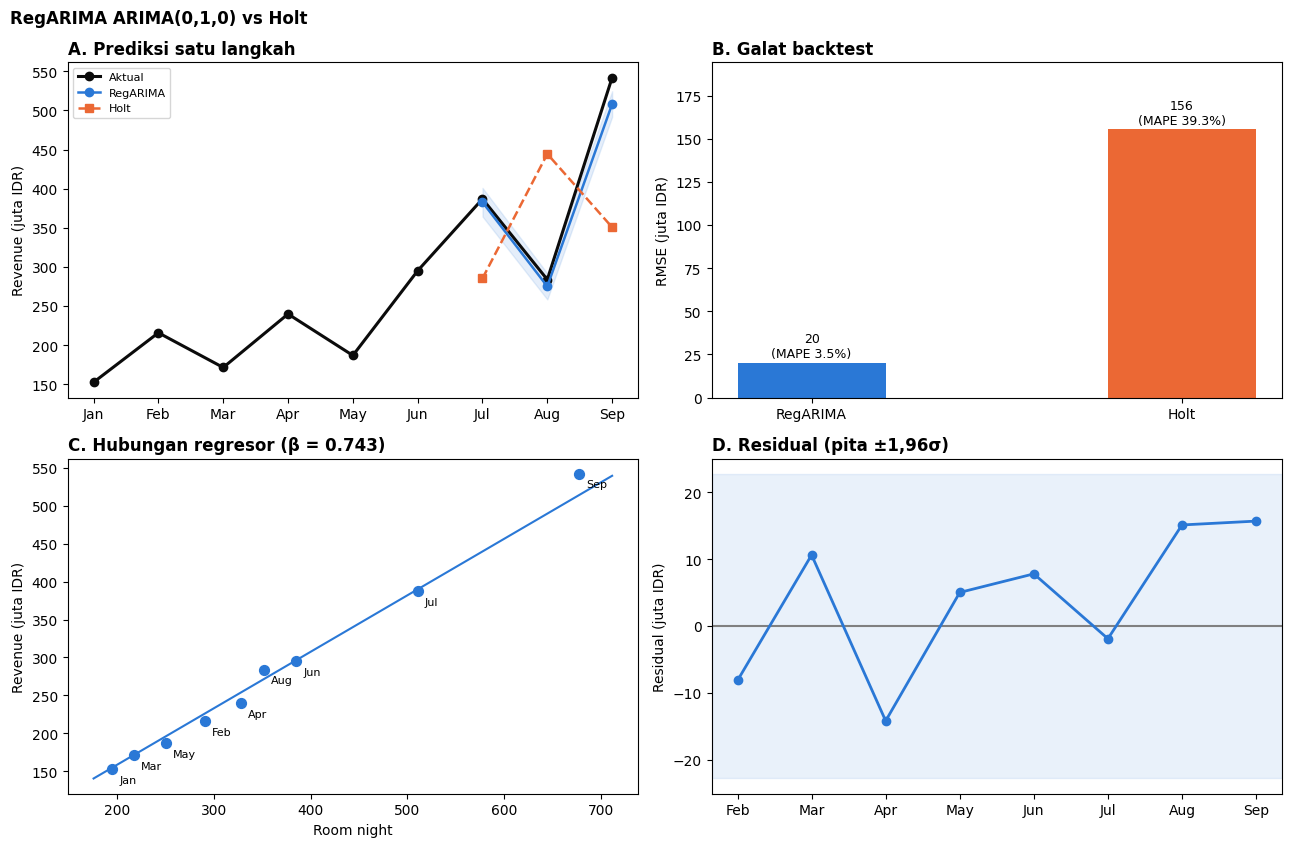

In [ ]:
BIRU, ORANYE, INK = '#2a78d6', '#eb6834', '#0b0b0b'
fig, axs = plt.subplots(2, 2, figsize=(13, 8.6))

# A. prediksi satu langkah
ax = axs[0, 0]; xs = np.arange(n); tx = [bulan.index(b) for b in bt.bulan]
ax.plot(xs, y, color=INK, lw=2.2, marker='o', label='Aktual')
for col, clr, mk in [('RegARIMA', BIRU, 'o'), ('Holt', ORANYE, 's')]:
    ax.plot(tx, bt[col], color=clr, marker=mk, lw=1.8, ls='-' if col == 'RegARIMA' else '--', label=col)
ax.fill_between(tx, bt.RegARIMA - 1.96 * bt.sigma, bt.RegARIMA + 1.96 * bt.sigma, color=BIRU, alpha=.12)
ax.set_xticks(xs); ax.set_xticklabels(bulan); ax.set_ylabel('Revenue (juta IDR)')
ax.set_title('A. Prediksi satu langkah', loc='left', fontweight='bold'); ax.legend(fontsize=8)

# B. RMSE
ax = axs[0, 1]
vals = metrik.loc[metode, 'RMSE']
bars = ax.bar([m.replace('_', '\n') for m in metode], vals, color=[BIRU, ORANYE], width=.4)
for b_, m in zip(bars, metode):
    ax.text(b_.get_x() + b_.get_width()/2, metrik.loc[m, 'RMSE'] + 3,
            f"{metrik.loc[m,'RMSE']:.0f}\n(MAPE {metrik.loc[m,'MAPE']:.1f}%)", ha='center', fontsize=9)
ax.set_ylim(0, vals.max() * 1.25); ax.set_ylabel('RMSE (juta IDR)')
ax.set_title('B. Galat backtest', loc='left', fontweight='bold')

# C. hubungan regresor
ax = axs[1, 0]
ax.scatter(x, y, color=BIRU, s=50, zorder=3)
for xi, yi, m in zip(x, y, bulan): ax.annotate(m, (xi, yi), xytext=(5, -10), textcoords='offset points', fontsize=8)
xx = np.linspace(x.min() * .9, x.max() * 1.05, 20)
ax.plot(xx, y.mean() + beta * (xx - x.mean()), color=BIRU)
ax.set_xlabel('Room night'); ax.set_ylabel('Revenue (juta IDR)')
ax.set_title(f'C. Hubungan regresor (β = {beta:.3f})', loc='left', fontweight='bold')

# D. residual
ax = axs[1, 1]
ax.axhline(0, color='gray'); ax.axhspan(-1.96 * sigma, 1.96 * sigma, color=BIRU, alpha=.10)
ax.plot(range(1, n), res, color=BIRU, marker='o', lw=2)
ax.set_xticks(range(1, n)); ax.set_xticklabels(bulan[1:]); ax.set_ylabel('Residual (juta IDR)')
ax.set_title('D. Residual (pita ±1,96σ)', loc='left', fontweight='bold')

plt.suptitle(f'RegARIMA {best.spesifikasi.split(" drift")[0]} vs Holt', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()